<a href="https://colab.research.google.com/github/Axcelini/Prediccion_precio_vehiculos.ipynb/blob/main/prediccion_precio_vehiculos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

RANDOM_STATE = 42  # fijamos la semilla para que todo sea reproducible


## 2. Descripción de los datos



In [ ]:
try:
    from google.colab import files
    uploaded = files.upload()  # selecciona vehiculos_actividad2.csv
    nombre_archivo = list(uploaded.keys())[0]
except ImportError:
    # Si no estamos en Colab, se asume que el csv ya está en la misma carpeta
    nombre_archivo = "vehiculos_actividad2.csv"

df = pd.read_csv(nombre_archivo)
print("Filas y columnas:", df.shape)
df.head()


Saving vehiculos_actividad2.csv to vehiculos_actividad2 (1).csv
Filas y columnas: (1000, 16)


,marca,anio,kilometraje,potencia_hp,cilindrada,puertas,pasajeros,consumo_l_100km,bateria_kwh,autonomia_km,seguridad_score,equipamiento_score,transmision,tipo_combustible,tipo_vehiculo,precio
0,Tesla,2018,102888,241,3.5,4,5,10.5,0.0,0,7.3,9.9,Manual,Gasolina,Hatchback,795100.0
1,Chevrolet,2025,3188,330,3.5,4,5,9.9,0.0,0,8.0,9.3,Automática,Gasolina,SUV,1313900.0
2,Hyundai,2021,85501,230,2.5,4,5,4.3,7.9,0,8.1,6.6,Automática,Híbrido,Pickup,666100.0
3,Nissan,2021,15532,217,2.0,4,5,5.8,10.2,35,7.1,7.3,Directa (EV),Híbrido,Crossover,826700.0
4,Tesla,2022,80570,237,3.0,4,5,8.2,0.0,0,9.6,7.1,CVT,Gasolina,Hatchback,801100.0


**Variables del dataset:**

| Variable | Tipo | Descripción |
|---|---|---|
| marca | categórica | Marca del vehículo (10 marcas) |
| anio | numérica | Año del modelo |
| kilometraje | numérica | Kilómetros recorridos |
| potencia_hp | numérica | Potencia del motor en caballos de fuerza |
| cilindrada | numérica | Cilindrada del motor en litros |
| puertas | numérica | Número de puertas |
| pasajeros | numérica | Capacidad de pasajeros |
| consumo_l_100km | numérica | Consumo de combustible (litros / 100 km) |
| bateria_kwh | numérica | Capacidad de batería (para híbridos/eléctricos) |
| autonomia_km | numérica | Autonomía en modo eléctrico |
| seguridad_score | numérica | Puntaje de seguridad (0-10) |
| equipamiento_score | numérica | Puntaje de equipamiento/tecnología (0-10) |
| transmision | categórica | Manual, Automática, CVT, Directa (EV) |
| tipo_combustible | categórica | Gasolina, Híbrido, Eléctrico |
| tipo_vehiculo | categórica | Hatchback, SUV, Pickup, Crossover, Sedán |
| **precio** | **numérica (target)** | Precio de venta del vehículo |


In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   marca               1000 non-null   object 
 1   anio                1000 non-null   int64  
 2   kilometraje         1000 non-null   int64  
 3   potencia_hp         1000 non-null   int64  
 4   cilindrada          1000 non-null   float64
 5   puertas             1000 non-null   int64  
 6   pasajeros           1000 non-null   int64  
 7   consumo_l_100km     1000 non-null   float64
 8   bateria_kwh         1000 non-null   float64
 9   autonomia_km        1000 non-null   int64  
 10  seguridad_score     1000 non-null   float64
 11  equipamiento_score  1000 non-null   float64
 12  transmision         1000 non-null   object 
 13  tipo_combustible    1000 non-null   object 
 14  tipo_vehiculo       1000 non-null   object 
 15  precio              1000 non-null   float64
dtypes: floa

In [ ]:
# checamos que no haya nulos y vemos estadísticas generales
print("Valores nulos por columna:")
print(df.isnull().sum())
df.describe().T


Valores nulos por columna:
marca                 0
anio                  0
kilometraje           0
potencia_hp           0
cilindrada            0
puertas               0
pasajeros             0
consumo_l_100km       0
bateria_kwh           0
autonomia_km          0
seguridad_score       0
equipamiento_score    0
transmision           0
tipo_combustible      0
tipo_vehiculo         0
precio                0
dtype: int64


,count,mean,std,min,25%,50%,75%,max
anio,1000.0,2021.9720,2.616115,2018.0,2020.00,2022.0,2024.000,2026.0
kilometraje,1000.0,54502.7790,37541.117287,0.0,23499.75,48144.0,80266.000,206963.0
potencia_hp,1000.0,226.8190,91.930242,70.0,162.00,211.0,272.000,547.0
cilindrada,1000.0,1.6433,1.007477,0.0,1.00,1.8,2.500,3.5
puertas,1000.0,4.0520,0.831858,2.0,4.00,4.0,5.000,5.0
pasajeros,1000.0,4.8700,0.967490,2.0,5.00,5.0,5.000,7.0
consumo_l_100km,1000.0,4.6430,2.734533,0.0,4.50,4.8,5.700,11.6
bateria_kwh,1000.0,17.4258,29.091042,0.0,0.00,2.0,15.100,99.9
autonomia_km,1000.0,82.8700,157.228579,0.0,0.00,0.0,52.000,591.0
seguridad_score,1000.0,8.0260,1.174838,6.0,7.00,8.0,9.100,10.0


### 2. Descripción de los datos (continuación) — Análisis exploratorio



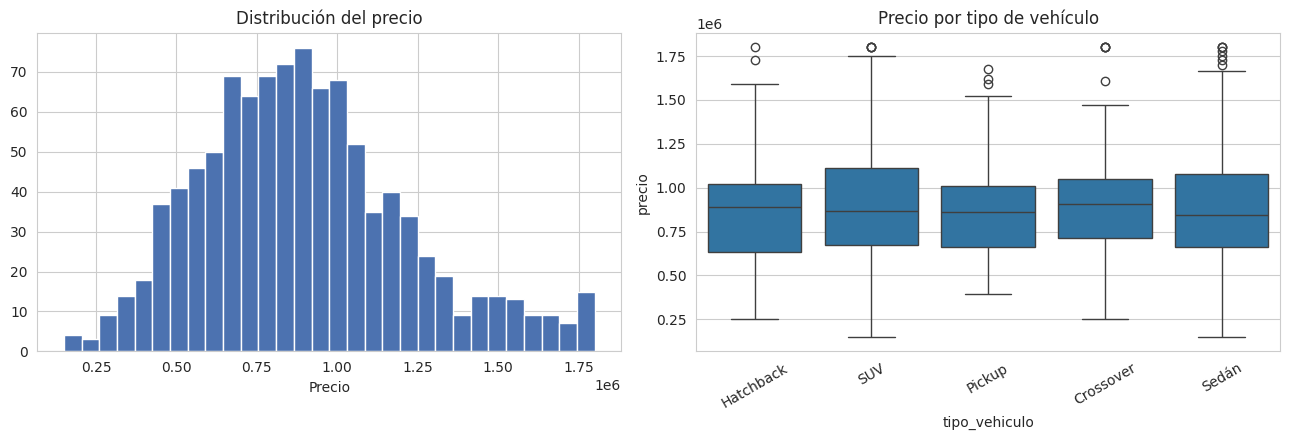

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].hist(df["precio"], bins=30, color="#4C72B0", edgecolor="white")
axes[0].set_title("Distribución del precio")
axes[0].set_xlabel("Precio")

sns.boxplot(x="tipo_vehiculo", y="precio", data=df, ax=axes[1])
axes[1].set_title("Precio por tipo de vehículo")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()


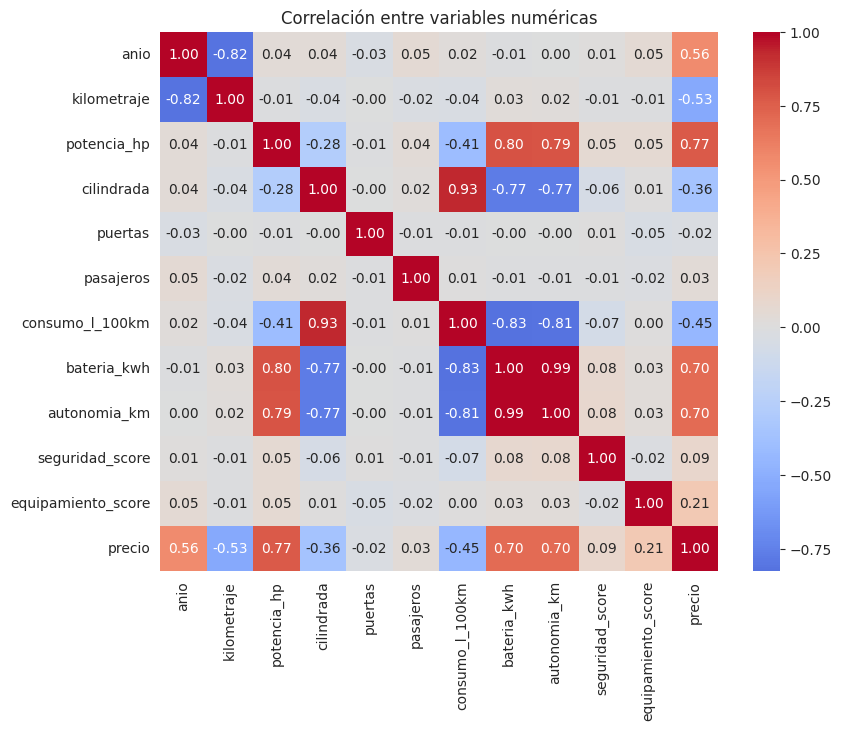

Correlación de cada variable con el precio:
precio                1.000000
potencia_hp           0.770036
bateria_kwh           0.704701
autonomia_km          0.703244
anio                  0.563333
equipamiento_score    0.212144
seguridad_score       0.094038
pasajeros             0.034586
puertas              -0.020772
cilindrada           -0.359254
consumo_l_100km      -0.447524
kilometraje          -0.534542
Name: precio, dtype: float64


In [ ]:
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
corr = df[num_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlación entre variables numéricas")
plt.show()

print("Correlación de cada variable con el precio:")
print(corr["precio"].sort_values(ascending=False))


## 3. Preprocesamiento



In [ ]:
cat_cols = ["marca", "transmision", "tipo_combustible", "tipo_vehiculo"]
num_cols = [c for c in df.columns if c not in cat_cols + ["precio"]]

X = df.drop(columns=["precio"])
y = df["precio"]

print("Columnas numéricas:", num_cols)
print("Columnas categóricas:", cat_cols)


Columnas numéricas: ['anio', 'kilometraje', 'potencia_hp', 'cilindrada', 'puertas', 'pasajeros', 'consumo_l_100km', 'bateria_kwh', 'autonomia_km', 'seguridad_score', 'equipamiento_score']
Columnas categóricas: ['marca', 'transmision', 'tipo_combustible', 'tipo_vehiculo']


## 4. División de los datos



In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print("Train:", X_train.shape, " Test:", X_test.shape)


Train: (800, 15)  Test: (200, 15)


In [ ]:
# One-Hot Encoding
X_train_enc = pd.get_dummies(X_train, columns=cat_cols, drop_first=True)
X_test_enc = pd.get_dummies(X_test, columns=cat_cols, drop_first=True)

# por si en test faltara alguna categoría que sí salió en train
X_test_enc = X_test_enc.reindex(columns=X_train_enc.columns, fill_value=0)

dummy_cols = [c for c in X_train_enc.columns if c not in num_cols]
print("Features numéricas:", len(num_cols), " | Features dummy generadas:", len(dummy_cols))

# Escalado solo de las variables numéricas
scaler = StandardScaler()
X_train_num = scaler.fit_transform(X_train_enc[num_cols])
X_test_num = scaler.transform(X_test_enc[num_cols])

# Set final para el modelo lineal: numéricas escaladas + dummies
X_train_final = np.hstack([X_train_num, X_train_enc[dummy_cols].values])
X_test_final = np.hstack([X_test_num, X_test_enc[dummy_cols].values])

print("Shape final X_train:", X_train_final.shape)


Features numéricas: 11  | Features dummy generadas: 18
Shape final X_train: (800, 29)


## 5. Baseline



In [ ]:
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train_final, y_train)
pred_baseline = baseline.predict(X_test_final)

mae_base = mean_absolute_error(y_test, pred_baseline)
rmse_base = np.sqrt(mean_squared_error(y_test, pred_baseline))
r2_base = r2_score(y_test, pred_baseline)

print(f"Baseline -> MAE: {mae_base:,.0f}  RMSE: {rmse_base:,.0f}  R2: {r2_base:.4f}")


Baseline -> MAE: 255,598  RMSE: 328,199  R2: -0.0057


## 6. Regresión lineal



In [ ]:
lin_reg = LinearRegression()
lin_reg.fit(X_train_final, y_train)

pred_lr_train = lin_reg.predict(X_train_final)
pred_lr_test = lin_reg.predict(X_test_final)

mae_lr = mean_absolute_error(y_test, pred_lr_test)
rmse_lr = np.sqrt(mean_squared_error(y_test, pred_lr_test))
r2_lr_test = r2_score(y_test, pred_lr_test)
r2_lr_train = r2_score(y_train, pred_lr_train)

print(f"Regresión Lineal -> MAE: {mae_lr:,.0f}  RMSE: {rmse_lr:,.0f}")
print(f"R2 train: {r2_lr_train:.4f}   R2 test: {r2_lr_test:.4f}")


Regresión Lineal -> MAE: 29,274  RMSE: 37,327
R2 train: 0.9867   R2 test: 0.9870


## 7. Regresión polinómica



In [ ]:
def construir_features_polinomicas(grado):
    poly = PolynomialFeatures(degree=grado, include_bias=False)
    train_poly = poly.fit_transform(X_train_num)
    test_poly = poly.transform(X_test_num)
    train_full = np.hstack([train_poly, X_train_enc[dummy_cols].values])
    test_full = np.hstack([test_poly, X_test_enc[dummy_cols].values])
    return train_full, test_full, train_poly.shape[1]


resultados_poly = []

for grado in [1, 2, 3, 4]:
    Xtr, Xte, n_features_poly = construir_features_polinomicas(grado)
    modelo = LinearRegression()
    modelo.fit(Xtr, y_train)

    pred_tr = modelo.predict(Xtr)
    pred_te = modelo.predict(Xte)

    resultados_poly.append({
        "grado": grado,
        "n_features_poly": n_features_poly,
        "MAE": mean_absolute_error(y_test, pred_te),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred_te)),
        "R2_train": r2_score(y_train, pred_tr),
        "R2_test": r2_score(y_test, pred_te),
    })

df_poly = pd.DataFrame(resultados_poly)
df_poly


,grado,n_features_poly,MAE,RMSE,R2_train,R2_test
0,1,11,29273.876170,3.732747e+04,0.986657,0.986991
1,2,77,30541.244735,3.754407e+04,0.988299,0.986840
2,3,363,49960.486412,6.636817e+04,0.994023,0.958875
3,4,1364,550475.867254,1.565597e+06,1.000000,-21.884922


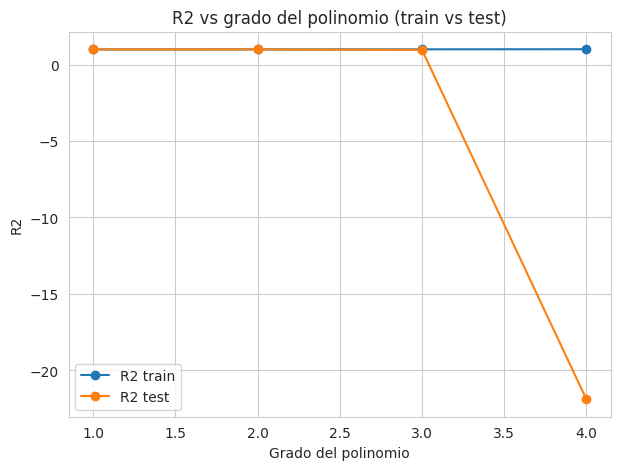

In [ ]:
plt.figure(figsize=(7, 5))
plt.plot(df_poly["grado"], df_poly["R2_train"], marker="o", label="R2 train")
plt.plot(df_poly["grado"], df_poly["R2_test"], marker="o", label="R2 test")
plt.xlabel("Grado del polinomio")
plt.ylabel("R2")
plt.title("R2 vs grado del polinomio (train vs test)")
plt.legend()
plt.show()


## 8. Validación cruzada



In [ ]:
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# CV para regresión lineal
cv_scores_lr = cross_val_score(LinearRegression(), X_train_final, y_train, cv=kf, scoring="r2")

# CV para polinómica grado 2
Xtr_poly2, _, _ = construir_features_polinomicas(2)
cv_scores_poly2 = cross_val_score(LinearRegression(), Xtr_poly2, y_train, cv=kf, scoring="r2")

print("Lineal      -> R2 por fold:", np.round(cv_scores_lr, 4))
print("Lineal      -> R2 promedio: %.4f (+/- %.4f)" % (cv_scores_lr.mean(), cv_scores_lr.std()))
print()
print("Poly grado2 -> R2 por fold:", np.round(cv_scores_poly2, 4))
print("Poly grado2 -> R2 promedio: %.4f (+/- %.4f)" % (cv_scores_poly2.mean(), cv_scores_poly2.std()))


Lineal      -> R2 por fold: [0.9874 0.9831 0.984  0.986  0.9866]
Lineal      -> R2 promedio: 0.9854 (+/- 0.0016)

Poly grado2 -> R2 por fold: [0.9851 0.9806 0.9805 0.9863 0.9862]
Poly grado2 -> R2 promedio: 0.9838 (+/- 0.0026)


## 9. Métricas



In [ ]:
tabla_comparativa = pd.DataFrame([
    {"Modelo": "Baseline", "MAE": mae_base, "RMSE": rmse_base, "R2_test": r2_base},
    {"Modelo": "Regresión Lineal", "MAE": mae_lr, "RMSE": rmse_lr, "R2_test": r2_lr_test},
] + [
    {"Modelo": f"Polinómica grado {row['grado']}", "MAE": row["MAE"], "RMSE": row["RMSE"], "R2_test": row["R2_test"]}
    for _, row in df_poly.iterrows()
])

tabla_comparativa = tabla_comparativa.round(2)
tabla_comparativa


,Modelo,MAE,RMSE,R2_test
0,Baseline,255597.80,328199.10,-0.01
1,Regresión Lineal,29273.88,37327.47,0.99
2,Polinómica grado 1.0,29273.88,37327.47,0.99
3,Polinómica grado 2.0,30541.24,37544.07,0.99
4,Polinómica grado 3.0,49960.49,66368.17,0.96
5,Polinómica grado 4.0,550475.87,1565597.25,-21.88


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful

## 10. Visualización



In [ ]:
residuales_lr = y_test - pred_lr_test

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].scatter(pred_lr_test, residuales_lr, alpha=0.5, color="#4C72B0")
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_xlabel("Precio predicho")
axes[0].set_ylabel("Residual (real - predicho)")
axes[0].set_title("Residuales vs Predicción - Regresión Lineal")

axes[1].hist(residuales_lr, bins=30, color="#55A868", edgecolor="white")
axes[1].set_title("Distribución de los residuales")
axes[1].set_xlabel("Residual")

plt.tight_layout()
plt.show()


In [ ]:
plt.figure(figsize=(6.5, 6))
plt.scatter(y_test, pred_lr_test, alpha=0.5, color="#4C72B0")
lims = [min(y_test.min(), pred_lr_test.min()), max(y_test.max(), pred_lr_test.max())]
plt.plot(lims, lims, "r--", label="Predicción perfecta")
plt.xlabel("Precio real")
plt.ylabel("Precio predicho")
plt.title("Precio real vs predicho - Regresión Lineal")
plt.legend()
plt.show()


## 11. Comparación
Con la tabla comparativa y las gráficas de arriba, el mejor modelo es la Regresión Lineal (o, de forma casi empatada, la Polinómica de grado 2):

Tiene de los mejores R² en test.
El R² de train y test están parejos → no hay sobreajuste.
Es el modelo más simple, con menos features, lo que lo hace más fácil de interpretar y menos costoso computacionalmente que la polinómica.
La Cross Validation confirma que su desempeño es estable entre folds.
La polinómica de grado 2 da resultados muy similares, pero a partir de grado 3 el modelo se degrada rápido por overfitting, así que no vale la pena la complejidad extra.


## 12. Predicción



In [ ]:
vehiculo_nuevo = pd.DataFrame([{
    "marca": "Toyota",
    "anio": 2025,
    "kilometraje": 5000,
    "potencia_hp": 210,
    "cilindrada": 2.0,
    "puertas": 4,
    "pasajeros": 5,
    "consumo_l_100km": 6.5,
    "bateria_kwh": 0.0,
    "autonomia_km": 0,
    "seguridad_score": 8.5,
    "equipamiento_score": 8.0,
    "transmision": "Automática",
    "tipo_combustible": "Gasolina",
    "tipo_vehiculo": "SUV",
}])

# aplicamos el mismo preprocesamiento que usamos en train
nuevo_enc = pd.get_dummies(vehiculo_nuevo, columns=cat_cols, drop_first=True)
nuevo_enc = nuevo_enc.reindex(columns=X_train_enc.columns, fill_value=0)

nuevo_num = scaler.transform(nuevo_enc[num_cols])
nuevo_final = np.hstack([nuevo_num, nuevo_enc[dummy_cols].values])

precio_predicho = lin_reg.predict(nuevo_final)[0]
print(f"Precio estimado para el vehículo nuevo: ${precio_predicho:,.0f}")
